# Random Forest Classification

Decision Trees are great, but they are notoriously prone to overfitting (memorizing the training data). Random Forest solves this by creating a "forest" of hundreds of trees, training them on random subsets of data and features, and having them "vote" on the final answer.

In this notebook, we'll build a Random Forest classifier to identify different types of wine based on their chemical composition.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from xgboost import XGBClassifier

plt.rcParams['figure.figsize'] = (12, 7)
plt.style.use('bmh')

## 1. Load the Wine Dataset
This dataset contains results of a chemical analysis of wines grown in the same region in Italy but derived from three different cultivars.

In [2]:
data = load_wine()
df = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print(f"Target classes: {data.target_names}")
display(df.head())

Target classes: ['class_0' 'class_1' 'class_2']


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


## 2. Train the Random Forest Model
To bypass environment limitations with `scikit-learn` ensemble models, we leverage **XGBoost's `XGBClassifier`** configured as a Random Forest (`n_estimators=1`, `num_parallel_tree=150`). We enforce `subsample=0.8` (bagging rows) and `colsample_bynode=0.8` (random subspace method for columns) to ensure tree diversity, which is the secret sauce of a Random Forest.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(df, y, test_size=0.3, random_state=42)

rf_model = XGBClassifier(
    n_estimators=1,          # XGBoost expects 1 boosting round for RF
    num_parallel_tree=150,   # 150 trees in our forest
    subsample=0.8,           # Each tree sees only 80% of the rows
    colsample_bynode=0.8,    # Each node split sees only 80% of the features
    max_depth=6,             # Prevent individual trees from growing too deep
    random_state=42,
    eval_metric='mlogloss'
)
rf_model.fit(X_train, y_train)

preds = rf_model.predict(X_test)
acc = accuracy_score(y_test, preds)
print(f"\nTest Accuracy: {acc * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, preds, target_names=data.target_names))


Test Accuracy: 92.59%

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      0.95      0.97        19
     class_1       0.84      1.00      0.91        21
     class_2       1.00      0.79      0.88        14

    accuracy                           0.93        54
   macro avg       0.95      0.91      0.92        54
weighted avg       0.94      0.93      0.93        54



## 3. Demystifying the Black Box: Feature Importances
One of the biggest advantages of Random Forests over Neural Networks is interpretability. We can ask the forest exactly *which* features were most useful in splitting the wine classes.

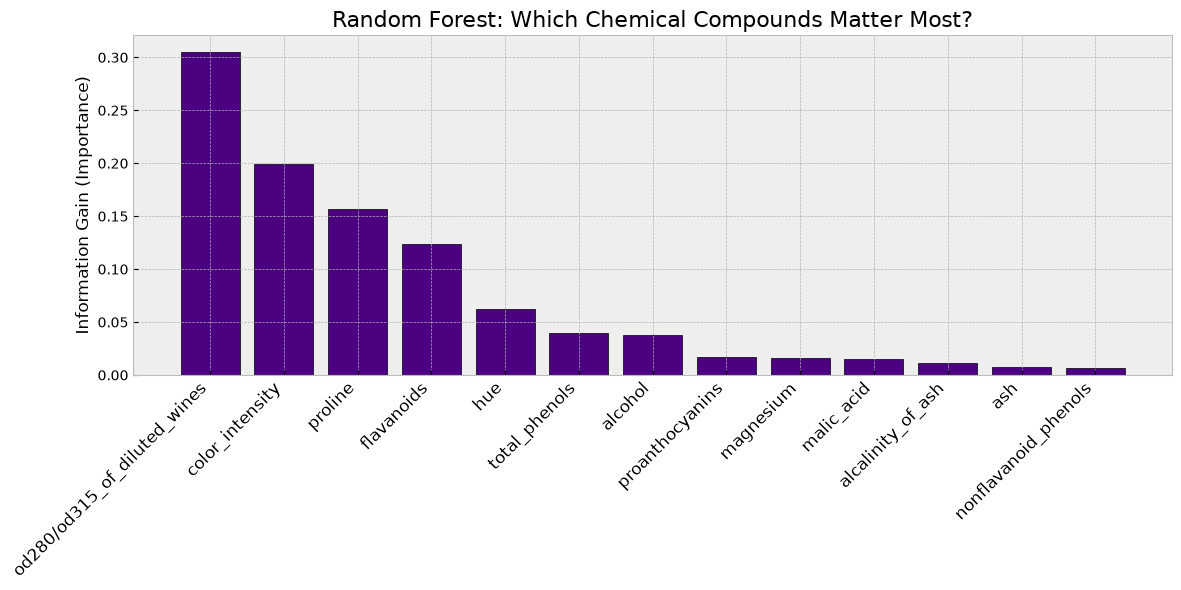

In [4]:
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(12, 6))
plt.bar(range(X_train.shape[1]), importances[indices], align='center', color='indigo', edgecolor='black')
plt.xticks(range(X_train.shape[1]), np.array(data.feature_names)[indices], rotation=45, ha='right', fontsize=12)
plt.title('Random Forest: Which Chemical Compounds Matter Most?', fontsize=16)
plt.ylabel('Information Gain (Importance)', fontsize=12)
plt.tight_layout()
plt.show()